<a href="https://colab.research.google.com/github/Apekshagaonkar/ai-systems-notebooks/blob/main/week5_llms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# What we covered so far
| Week | What we covered |
|---|---|
| Week 1 | **Python classes.** `__init__`, methods, `self`, and breaking one on purpose |
| Week 2 | **Regression.** Predicting temperature with linear regression, scored with RMSE and R² |
| Week 3 | **Classification.** Predicting good/skip days with KNN and logistic regression, scored with precision/recall, then saving the model |
| Week 4 | **Reusable component.** Wrapping the saved model in a tested `WeatherClassifier` package |
| Week 5 | **LLMs.** Tokens, embeddings, the Chat Completions API, memory and prompting |

# Week 5 — Introduction to AI and LLMs
### How a "next-word guesser" turns into ChatGPT, and how we talk to it from Python

Your phone keyboard already does this: type *"see you"* and it suggests *"tomorrow"*.
A Large Language Model is that same idea: **guess the next piece of text**, trained on a huge pile of text.

Today we build the tiny version ourselves, then use the real thing through an API.


**No API key? No problem.** Everything runs for free with a *pretend* model (`MockLLM`).
If you have an OpenAI key, add it and the same cells talk to the real model.

## Setup — run this first
Installs the tokenizer and picks the model: the **real** OpenAI model if you've added a key, otherwise the free **pretend** one.

*Optional:* to use a real key in Colab, click 🔑 (Secrets) on the left, add `OPENAI_API_KEY`, and turn on notebook access.

Tokenizer: the chopping machine that cuts text into tokens before the model reads it.

In [ ]:
!pip -q install tiktoken openai

import os, re, random
from collections import Counter, defaultdict
from types import SimpleNamespace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODEL = "gpt-4o"   # the model from the slides; change it if your provider has retired it

# ---- tokenizer (Chapter 2 explains it) ----
try:
    import tiktoken
    enc = tiktoken.get_encoding("o200k_base")          # GPT-4o's tokenizer
    def tokenize(text):
        return [enc.decode_single_token_bytes(t).decode("utf-8", "replace") for t in enc.encode(text)]
    TOKENIZER = "GPT-4o tokenizer (o200k_base)"
except Exception:
    def tokenize(text):                                # rough stand-in: ~4 characters per token
        return re.findall(r".{1,4}", text, flags=re.S)
    TOKENIZER = "rough estimate (~4 characters per token), tiktoken unavailable"

def count_tokens(text):
    return len(tokenize(text))

def count_message_tokens(messages):
    """About how many tokens a list of chat messages costs (roles add a few extra tokens each)."""
    return sum(count_tokens(m["content"]) + 4 for m in messages)

# ---- the pretend model ----
class MockLLM:
    """A pretend LLM with the same shape as the real OpenAI client.
    Like the real one, it has NO memory: it only sees the messages you pass in."""
    CLOUD_FACTS = [
        "Clouds are made of billions of tiny water droplets floating in the air.",
        "A big fluffy cumulus cloud can weigh as much as 100 elephants.",
        "Clouds look white because they scatter all colours of sunlight equally.",
        "Fog is just a cloud that touches the ground.",
    ]

    def __init__(self):
        self.chat = SimpleNamespace(completions=SimpleNamespace(create=self._create))

    def _answer(self, messages, temperature):
        users = [m["content"] for m in messages if m["role"] == "user"]
        last = users[-1].lower() if users else ""
        if "what is my name" in last or "what's my name" in last:
            for u in users:
                found = re.search(r"my name is (\w+)", u, flags=re.I)
                if found:
                    return f"Your name is {found.group(1)}."
            return "I don't know your name. You haven't told me in this conversation."
        found = re.search(r"my name is (\w+)", last, flags=re.I)
        if found:
            return f"Nice to meet you, {found.group(1).capitalize()}!"
        if "token" in last:
            return "A token is a small chunk of text, about 3-4 characters, that a language model reads instead of whole words."
        if "cloud" in last:
            if temperature < 0.5:
                return self.CLOUD_FACTS[0]            # low temperature: always the safest answer
            return random.choice(self.CLOUD_FACTS)    # high temperature: varied answers
        return ("(pretend model) I can only answer a few demo questions. "
                "Add an OPENAI_API_KEY in Setup to get real answers to prompts like this one.")

    def _create(self, model, messages, temperature=1.0, **kwargs):
        system = " ".join(m["content"] for m in messages if m["role"] == "system").lower()
        reply = self._answer(messages, temperature)
        if "pirate" in system:
            reply = "Arrr! " + reply + " Yo-ho-ho, matey!"
        usage = SimpleNamespace(prompt_tokens=count_message_tokens(messages),
                                completion_tokens=count_tokens(reply))
        usage.total_tokens = usage.prompt_tokens + usage.completion_tokens
        message = SimpleNamespace(role="assistant", content=reply)
        return SimpleNamespace(model="pretend-" + model, usage=usage,
                               choices=[SimpleNamespace(index=0, message=message, finish_reason="stop")])

# ---- pick real or pretend ----
key = os.environ.get("OPENAI_API_KEY")
try:
    from google.colab import userdata
    key = key or userdata.get("OPENAI_API_KEY")
except Exception:
    pass

if key:
    from openai import OpenAI
    client = OpenAI(api_key=key)
    REAL_API = True
else:
    client = MockLLM()
    REAL_API = False

print("Tokenizer:", TOKENIZER)
print("Model:    ", f"REAL {MODEL}" if REAL_API else "pretend model (MockLLM), free, no key needed")

Tokenizer: GPT-4o tokenizer (o200k_base)
Model:     pretend model (MockLLM), free, no key needed


---
## Opening — what is an LLM?  *(0–5 min)*

A **neural network** trained on an enormous amount of text (books, web pages, code) to do one job:

> **predict what comes next.**

Do that at massive scale and something surprising appears: it can answer questions, write code, summarise, translate.

You'll never train one in this course. You'll **use** them through an **API**.

| LLM | Made by | Note |
|---|---|---|
| ChatGPT (GPT-4o family) | OpenAI | |
| Claude | Anthropic | |
| Gemini | Google | |
| Llama | Meta | open weights, can run on your own machine |

Different training data, different design choices. **Same core idea.**

---
## Chapter 1 — Build a tiny next-word guesser  *(5–15 min)*

How could a computer learn "what comes next"? The simplest way: **count**.

Read a lot of text. Every time you see two words, note which word came after them.

In [ ]:
weather_text = """
today is sunny . today is sunny . today is rainy .
tomorrow is sunny . tomorrow is cloudy .
i love sunny days . i love rainy days . i love pizza .
the sky is blue . the sky is grey .
"""

def train(text, context=2):
    """For every 2-word context, count which word came next."""
    words = text.lower().split()
    table = defaultdict(Counter)
    for i in range(len(words) - context):
        before = tuple(words[i:i + context])
        table[before][words[i + context]] += 1
    return table

def next_word_probs(table, prompt):
    """Turn the counts after the last two words into probabilities."""
    before = tuple(prompt.lower().split()[-2:])
    counts = table[before]
    total = sum(counts.values())
    return {word: round(n / total, 2) for word, n in counts.most_common()}

tiny_model = train(weather_text)
print("after 'today is'   →", next_word_probs(tiny_model, "today is"))
print("after 'i love'     →", next_word_probs(tiny_model, "i love"))

after 'today is'   → {'sunny': 0.67, 'rainy': 0.33}
after 'i love'     → {'sunny': 0.33, 'rainy': 0.33, 'pizza': 0.33}


### Writing a sentence = guess, add, repeat

This is slide 8, as code:
1. Start with a prompt
2. Get a probability for every possible next word
3. **Pick** one (sample) and add it
4. Repeat until done

In [ ]:
def generate(table, prompt, temperature=1.0, max_words=10):
    words = prompt.lower().split()
    for _ in range(max_words):
        probs = next_word_probs(table, " ".join(words))
        if not probs:
            break
        choices = list(probs)
        p = np.array(list(probs.values())) ** (1 / temperature)   # temperature reshapes the odds
        word = random.choices(choices, weights=p / p.sum())[0]   # roll the dice
        words.append(word)
        if word == ".":
            break
    return " ".join(words)

random.seed(1)
for _ in range(5):
    print(generate(tiny_model, "i love"))

i love sunny days .
i love sunny days .
i love rainy days .
i love sunny days .
i love pizza .


### Temperature — how adventurous is the dice roll?

- **Low (0.1–0.3):** the likely word almost always wins → focused, predictable
- **High (0.8–1.0+):** less likely words get a real chance → creative, varied

Let's see what temperature does to the odds.

In [ ]:
def with_temperature(probs, temperature):
    p = np.array(list(probs.values())) ** (1 / temperature)
    return {word: round(float(x), 3) for word, x in zip(probs, p / p.sum())}

odds = next_word_probs(tiny_model, "today is")
for t in [0.2, 1.0, 2.0]:
    print(f"temperature {t}: {with_temperature(odds, t)}")

temperature 0.2: {'sunny': 0.972, 'rainy': 0.028}
temperature 1.0: {'sunny': 0.67, 'rainy': 0.33}
temperature 2.0: {'sunny': 0.588, 'rainy': 0.412}


### Confidently wrong

Our model only knows what it read. What if what it read was wrong?

In [ ]:
facts_text = """
the capital of australia is sydney .
the capital of australia is sydney .
the capital of australia is sydney .
the capital of australia is canberra .
"""
facts_model = train(facts_text)
odds = next_word_probs(facts_model, "the capital of australia is")
print("Real counts:     ", odds)
print("Temperature 0.2: ", with_temperature(odds, 0.2))

Real counts:      {'sydney': 0.75, 'canberra': 0.25}
Temperature 0.2:  {'sydney': 0.996, 'canberra': 0.004}


---
## Chapter 2 — Tokens: what the model actually reads  *(15–22 min)*

Our tiny model used whole words. Real LLMs read **tokens**: chunks of about 3–4 characters.

Common words are one token. Rare or long words get split into pieces, like Lego bricks.
This splitting (**tokenization**) happens before any text enters the model.

In [ ]:
examples = ["hello", "unbelievable", "I love pizza",
            "Today is sunny in San Jose",
            "for i in range(10):",
            "नमस्ते, आप कैसे हैं?"]

rows = []
for text in examples:
    pieces = tokenize(text)
    rows.append({"text": text, "tokens": len(pieces), "characters": len(text),
                 "pieces": " | ".join(pieces)})
print(TOKENIZER)
pd.DataFrame(rows)

GPT-4o tokenizer (o200k_base)


,text,tokens,characters,pieces
0,hello,1,5,hello
1,unbelievable,3,12,un | bel | ievable
2,I love pizza,3,12,I | love | pizza
3,Today is sunny in San Jose,6,26,Today | is | sunny | in | San | Jose
4,for i in range(10):,7,19,for | i | in | range | ( | 10 | ):
5,"नमस्ते, आप कैसे हैं?",9,20,"न | म | स्त | े | , | आप | कैसे | हैं | ?"


### Why tokens matter: money and space

- **Cost:** most APIs charge **per token**, for what you send *and* what you get back.
- **Context limit:** a model can only read so many tokens at once (GPT-4o: **128,000**).
- **Non-English text and code** use more tokens per character.

Imagine our pipeline sends 10,000 weather reports to an LLM:

In [ ]:
report = ("Today in San Jose: max 24°C, min 13°C, no rain, light wind at 12 km/h. "
          "Our model predicts a GOOD day for a walk with 94% probability.")

PRICE_PER_MILLION_TOKENS = 2.50   # example price in USD; check your provider's current pricing
CONTEXT_LIMIT = 128_000           # GPT-4o, from the slide

per_report = count_tokens(report)
reports = 10_000
total = per_report * reports
print(f"One report:        {per_report} tokens")
print(f"{reports:,} reports:   {total:,} tokens")
print(f"Cost to send them: ${total / 1_000_000 * PRICE_PER_MILLION_TOKENS:.2f}")
print(f"Reports that fit in ONE request: {CONTEXT_LIMIT // per_report:,}")

One report:        41 tokens
10,000 reports:   410,000 tokens
Cost to send them: $1.02
Reports that fit in ONE request: 3,121


---
## Chapter 3 — Embeddings: meaning as numbers  *(22–30 min)*

Computers only do maths. So how does a model know *car* and *automobile* mean the same thing?

It turns each piece of text into a list of numbers: an **embedding**. Think of it as an **address on a map of meaning**.
Similar meanings → nearby addresses.

Real embeddings have hundreds of numbers, learned by the model. Ours has **4 numbers we picked by hand**, so we can read them:

In [ ]:
dimensions = ["royalty", "male(+) / female(-)", "vehicle", "food", "size"]
emb = {
    "king":       [0.95,  0.90, 0.00, 0.00, 0.00],
    "queen":      [0.95, -0.90, 0.00, 0.00, 0.00],
    "man":        [0.05,  0.90, 0.00, 0.00, 0.00],
    "woman":      [0.05, -0.90, 0.00, 0.00, 0.00],
    "car":        [0.00,  0.00, 0.90, 0.00, 0.30],
    "automobile": [0.00,  0.00, 0.88, 0.00, 0.33],
    "bus":        [0.00,  0.00, 0.60, 0.00, 0.90],
    "pizza":      [0.00,  0.00, 0.00, 0.95, 0.10],
}
emb = {w: np.array(v) for w, v in emb.items()}
pd.DataFrame(emb, index=dimensions).T

,royalty,male(+) / female(-),vehicle,food,size
king,0.95,0.9,0.00,0.00,0.00
queen,0.95,-0.9,0.00,0.00,0.00
man,0.05,0.9,0.00,0.00,0.00
woman,0.05,-0.9,0.00,0.00,0.00
car,0.00,0.0,0.90,0.00,0.30
automobile,0.00,0.0,0.88,0.00,0.33
bus,0.00,0.0,0.60,0.00,0.90
pizza,0.00,0.0,0.00,0.95,0.10


### How close are two meanings?

We measure the **angle** between two lists of numbers: **cosine similarity**.
`1.0` = same direction (same meaning), `0` = unrelated.

In [ ]:
def similarity(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

for a, b in [("car", "automobile"), ("car", "bus"), ("car", "pizza")]:
    print(f"{a:>5} vs {b:<10} {similarity(emb[a], emb[b]):.2f}")

  car vs automobile 1.00
  car vs bus        0.79
  car vs pizza      0.03


### The famous trick: king − man + woman = ?

Directions on the map mean something too (slide 7). Let's do arithmetic with meaning.

king - man + woman is closest to: queen


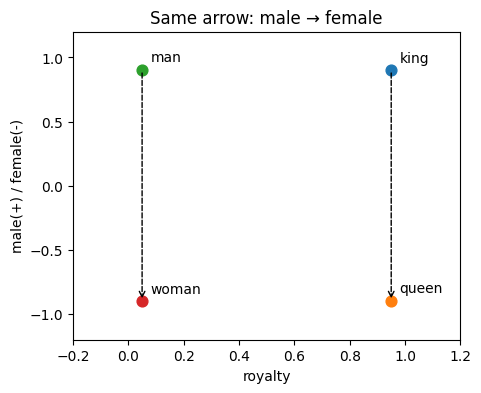

In [ ]:
target = emb["king"] - emb["man"] + emb["woman"]
ranked = sorted(emb, key=lambda w: similarity(emb[w], target), reverse=True)
print("king - man + woman is closest to:", ranked[0])

fig, ax = plt.subplots(figsize=(5, 4))
for w in ["king", "queen", "man", "woman"]:
    x, y = emb[w][0], emb[w][1]
    ax.scatter(x, y, s=60); ax.annotate(w, (x, y), textcoords="offset points", xytext=(6, 6))
ax.annotate("", xy=emb["queen"][:2], xytext=emb["king"][:2], arrowprops=dict(arrowstyle="->", ls="--"))
ax.annotate("", xy=emb["woman"][:2], xytext=emb["man"][:2], arrowprops=dict(arrowstyle="->", ls="--"))
ax.set_xlabel("royalty"); ax.set_ylabel("male(+) / female(-)")
ax.set_title("Same arrow: male → female"); ax.set_xlim(-0.2, 1.2); ax.set_ylim(-1.2, 1.2)
plt.show()

In [ ]:
# Optional: real embeddings (needs an API key)
if REAL_API:
    words = ["car", "automobile", "pizza"]
    data = client.embeddings.create(model="text-embedding-3-small", input=words).data
    real = {w: np.array(d.embedding) for w, d in zip(words, data)}
    print("Real embedding length:", len(real["car"]), "numbers")
    print("car vs automobile:", round(similarity(real["car"], real["automobile"]), 2))
    print("car vs pizza:     ", round(similarity(real["car"], real["pizza"]), 2))
else:
    print("Skipped: add an API key in Setup to compare real embeddings (about 1,500 numbers each).")

Skipped: add an API key in Setup to compare real embeddings (about 1,500 numbers each).


---
## Chapter 4 — Talking to an LLM: the Chat Completions API  *(30–38 min)*

Every message has a **role** and **content**:

| Role | What it is | Analogy |
|---|---|---|
| `system` | sets the model's behaviour | the job description you give a new employee |
| `user` | your prompt | the customer's question |
| `assistant` | the model's earlier replies | what the employee already said |

The model reads all messages **in order** and writes the next `assistant` message.

This is the code from slide 11 (the `client` was created in Setup):

In [ ]:
response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a helpful assistant. Don't reply"},
        {"role": "user",   "content": "What is a token?"},
    ],
)

print(response.choices[0].message.content)

A token is a small chunk of text, about 3-4 characters, that a language model reads instead of whole words.


### Open up the response

The answer is only part of what comes back:

In [ ]:
print("model:        ", response.model)
print("finish_reason:", response.choices[0].finish_reason)
print("tokens in:    ", response.usage.prompt_tokens)
print("tokens out:   ", response.usage.completion_tokens)
print("total tokens: ", response.usage.total_tokens)

model:         pretend-gpt-4o
finish_reason: stop
tokens in:     19
tokens out:    26
total tokens:  45


### Change the job description

Same question, different `system` message. *(This is the Kaggle Lesson 2 challenge.)*

In [ ]:
response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a pirate."},
        {"role": "user",   "content": "What is a token?"},
    ],
)
print(response.choices[0].message.content)

Arrr! A token is a small chunk of text, about 3-4 characters, that a language model reads instead of whole words. Yo-ho-ho, matey!


### Temperature, for real

Ask the same question three times at low temperature, then at high temperature.

In [ ]:
question = [{"role": "user", "content": "Tell me one interesting fact about clouds in one sentence."}]

for t in [0.2, 1.0]:
    print(f"--- temperature {t} ---")
    for _ in range(3):
        r = client.chat.completions.create(model=MODEL, messages=question, temperature=t)
        print("•", r.choices[0].message.content)

--- temperature 0.2 ---
• Clouds are made of billions of tiny water droplets floating in the air.
• Clouds are made of billions of tiny water droplets floating in the air.
• Clouds are made of billions of tiny water droplets floating in the air.
--- temperature 1.0 ---
• Fog is just a cloud that touches the ground.
• Clouds look white because they scatter all colours of sunlight equally.
• A big fluffy cumulus cloud can weigh as much as 100 elephants.


---
## Chapter 5 — The memory problem  *(38–46 min)*

Every API call is **stateless**: the model remembers **nothing** from earlier calls.

Imagine calling a help line where **a new person picks up every time**. They've never heard of you.
Let's see it happen.

In [ ]:
first = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "Hi! My name is Priya."}],
)
print("Call 1:", first.choices[0].message.content)

second = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "What is my name?"}],
)
print("Call 2:", second.choices[0].message.content)

Call 1: Nice to meet you, Priya!
Call 2: I don't know your name. You haven't told me in this conversation.


### The fix: send the whole conversation every time

Back to the help line: you read the new person **the full case file** at the start of each call.
That case file is a Python list, `messages`, and **your code** keeps it.

In [ ]:
messages = [{"role": "system", "content": "You are a helpful assistant."}]

def chat(user_input):
    messages.append({"role": "user", "content": user_input})
    response = client.chat.completions.create(model=MODEL, messages=messages)
    reply = response.choices[0].message.content
    messages.append({"role": "assistant", "content": reply})
    print(f"You: {user_input}")
    print(f"AI:  {reply}")
    print(f"     (messages sent: {len(messages) - 1}, tokens sent: {response.usage.prompt_tokens})\n")

chat("Hi! My name is Priya.")
chat("What is my name?")

You: Hi! My name is Priya.
AI:  Nice to meet you, Priya!
     (messages sent: 2, tokens sent: 22)

You: What is my name?
AI:  Your name is Priya.
     (messages sent: 4, tokens sent: 43)



### The catch: the case file keeps growing

Every turn re-sends **everything before it**. Let's simulate a long chat.

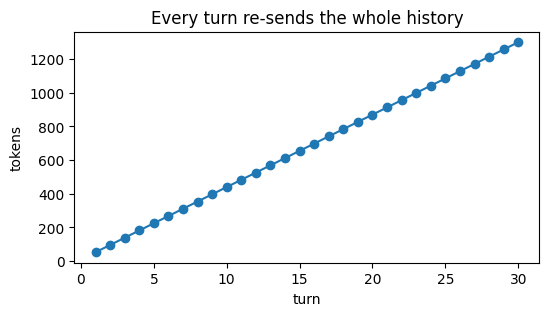

Total tokens paid for over 30 turns: 20,295


In [ ]:
history = [{"role": "system", "content": "You are a helpful assistant."}]
growth = []
for turn in range(1, 31):
    history.append({"role": "user", "content": f"Question {turn}: what should I wear if it's 18°C and windy in San Jose?"})
    history.append({"role": "assistant", "content": "A light jacket over a t-shirt, and maybe a scarf for the wind."})
    growth.append({"turn": turn, "tokens sent this turn": count_message_tokens(history)})

growth = pd.DataFrame(growth)
growth.plot(x="turn", y="tokens sent this turn", marker="o", legend=False,
            title="Every turn re-sends the whole history", figsize=(6, 3))
plt.ylabel("tokens"); plt.show()
print("Total tokens paid for over 30 turns:", f"{growth['tokens sent this turn'].sum():,}")

### Try the simplest fix: keep only recent messages

What do we lose? *(Kaggle Lesson 3: "what happens if you remove old messages")*

In [ ]:
def keep_recent(messages, n=2):
    """Keep the system message plus only the last n messages."""
    return messages[:1] + messages[-n:]

messages.append({"role": "user", "content": "Can you tell me a fact about clouds?"})
messages.append({"role": "assistant", "content": "Fog is just a cloud that touches the ground."})

short = keep_recent(messages) + [{"role": "user", "content": "What is my name?"}]
print("Sending only:")
for m in short:
    print(f"  {m['role']:>9}: {m['content'][:60]}")
reply = client.chat.completions.create(model=MODEL, messages=short).choices[0].message.content
print("\nAI:", reply)

Sending only:
     system: You are a helpful assistant.
       user: Can you tell me a fact about clouds?
  assistant: Fog is just a cloud that touches the ground.
       user: What is my name?

AI: I don't know your name. You haven't told me in this conversation.


---
## Chapter 6 — Prompt engineering: getting reliable answers  *(46–54 min)*

A model predicts *what likely comes next*. So **what you put before** the answer shapes the answer.

| Technique | What you send | Best for |
|---|---|---|
| **Zero-shot** | just the instruction | simple, common tasks |
| **One-shot** | one example + the input | showing the format once |
| **Few-shot** | 2–5 examples + the input | when format or style must be consistent |
| **Chain-of-thought** | "think step by step" | maths, logic, multi-step reasoning |

Prompts are just message lists. Let's build them.

*With the pretend model you'll see exactly what gets sent, but not a real answer. Kaggle Lesson 4 shows the real outputs side by side.*

In [ ]:
def ask(messages, temperature=0):
    r = client.chat.completions.create(model=MODEL, messages=messages, temperature=temperature)
    return r.choices[0].message.content

def show(messages):
    for m in messages:
        print(f"[{m['role']}] {m['content']}")

review = "The forecast app said sunny, I left my umbrella, and got soaked. Great."

zero_shot = [
    {"role": "user", "content": f"Classify this review as positive or negative.\n\nReview: {review}"},
]

few_shot = [
    {"role": "system", "content": "Classify each review. Reply with exactly one word: positive or negative."},
    {"role": "user", "content": "Review: Accurate every single morning. Love it."},
    {"role": "assistant", "content": "positive"},
    {"role": "user", "content": "Review: Crashes whenever I open the radar map."},
    {"role": "assistant", "content": "negative"},
    {"role": "user", "content": "Review: Wow, rain alerts arrive AFTER the rain. Brilliant."},
    {"role": "assistant", "content": "negative"},
    {"role": "user", "content": f"Review: {review}"},
]

print("=== ZERO-SHOT: what we send ==="); show(zero_shot)
print("\n→", ask(zero_shot))
print("\n=== FEW-SHOT: what we send ==="); show(few_shot)
print("\n→", ask(few_shot))

=== ZERO-SHOT: what we send ===
[user] Classify this review as positive or negative.

Review: The forecast app said sunny, I left my umbrella, and got soaked. Great.

→ (pretend model) I can only answer a few demo questions. Add an OPENAI_API_KEY in Setup to get real answers to prompts like this one.

=== FEW-SHOT: what we send ===
[system] Classify each review. Reply with exactly one word: positive or negative.
[user] Review: Accurate every single morning. Love it.
[assistant] positive
[user] Review: Crashes whenever I open the radar map.
[assistant] negative
[user] Review: Wow, rain alerts arrive AFTER the rain. Brilliant.
[assistant] negative
[user] Review: The forecast app said sunny, I left my umbrella, and got soaked. Great.

→ (pretend model) I can only answer a few demo questions. Add an OPENAI_API_KEY in Setup to get real answers to prompts like this one.


### Chain-of-thought: let it show its work

Like maths class: writing the steps catches mistakes. Try this classic puzzle.

In [ ]:
puzzle = ("A bat and a ball cost $1.10 in total. "
          "The bat costs $1.00 more than the ball. How much does the ball cost?")

direct = [{"role": "user", "content": puzzle + " Reply with only the number."}]
step_by_step = [{"role": "user", "content": puzzle + " Let's think step by step, then give the final answer."}]

print("=== DIRECT ===");        print(ask(direct))
print("\n=== STEP BY STEP ==="); print(ask(step_by_step))

=== DIRECT ===
(pretend model) I can only answer a few demo questions. Add an OPENAI_API_KEY in Setup to get real answers to prompts like this one.

=== STEP BY STEP ===
(pretend model) I can only answer a few demo questions. Add an OPENAI_API_KEY in Setup to get real answers to prompts like this one.


---
## Chapter 7 — Ethics: questions worth taking seriously  *(54–58 min)*

Our tiny model can show us one of these problems directly. Let's train it on some skewed text:

In [ ]:
skewed_text = """
the engineer said he would fix it . the engineer said he would fix it .
the engineer said he would fix it . the engineer said he would fix it .
the engineer said she would fix it .
the nurse said she would help . the nurse said she would help .
the nurse said she would help . the nurse said she would help .
the nurse said he would help .
"""
bias_model = train(skewed_text)
for job in ["engineer", "nurse"]:
    odds = next_word_probs(bias_model, f"the {job} said")
    print(f"the {job} said …   counts: {odds}   at temperature 0.2: {with_temperature(odds, 0.2)}")

the engineer said …   counts: {'he': 0.8, 'she': 0.2}   at temperature 0.2: {'he': 0.999, 'she': 0.001}
the nurse said …   counts: {'she': 0.8, 'he': 0.2}   at temperature 0.2: {'she': 0.999, 'he': 0.001}


| Concern | What it means |
|---|---|
| **Bias** | models inherit human biases from their training data, and can amplify them (you just saw it) |
| **Misinformation** | they produce *plausible* text, not verified facts. Confident falsehoods, at scale (Sydney!) |
| **Energy use** | training and running large models has real, debated environmental costs |
| **Labour displacement** | automating knowledge work affects real jobs, e.g. translation, writing, support |

These are active debates, not footnotes.

*Discussion:* Some argue we should slow down building more powerful AI. Others say the benefits outweigh the risks. Is there a position you find convincing, and why?

---
## Wrap-up  *(58–60 min)*

1. **LLMs** predict the next token. Trained at massive scale, they're powerful but not infallible.
2. **Temperature** controls the dice roll: low = consistent, high = creative.
3. **High probability ≠ true.** Check facts that matter.
4. **Tokens** are what models read and what you pay for. **Embeddings** turn meaning into numbers.
5. **Chat Completions**: a list of `{role, content}` messages in → one assistant message out.
6. **Stateless**: your code keeps the history and re-sends it, so watch the token count.
7. **Prompting**: examples (few-shot) fix the format; "step by step" improves reasoning.

### Where this fits in our pipeline
Last week our component returned `Prediction(label="good", probability=0.94)`.
In Weeks 10–11, an LLM can turn that into a sentence people want to read:

### Think about before next time
- Your chatbot has 1,000 users chatting for an hour. Which history-trimming strategy would you choose, and what might it forget?
- You need the LLM's answer to go straight into Python code. Which technique from today makes that reliable?
- Name one task you'd happily give an LLM, and one you wouldn't. What's the difference?